# Load B0  & Masks

In [8]:
from pathlib import Path
import numpy as np
import src.read_write as read_write
import src.utils as utils

dir_b0 = Path("data/all_b0_maps/")



techniques = ["CPROne", "CPRIter", "IDC", "IROC"]
positions = ["position1", "position2", "position3"]
orders = ["Order02", "Order04", "Order08", "Order12"]

b0_maps = {}

for position in positions:
    b0_maps[position] = {}

    for technique in techniques:

        # IDC has no order
        if technique == "IDC":
            matches = list(dir_b0.glob(f"*{position}*{technique}*.npy"))

            if len(matches) == 1:
                b0_maps[position][technique] = np.load(matches[0])*(-1)
            else:
                print(f"IDC problem: {position}")

        # Other techniques have orders
        else:
            b0_maps[position][technique] = {}

            for order in orders:
                matches = list(
                    dir_b0.glob(f"*{position}*{technique}*{order}*.npy")
                )

                if len(matches) == 1:
                    b0_maps[position][technique][order] = np.load(matches[0])

                else:
                    print(f"Missing/problem: {position}, {technique}, {order}")






# ---- Create Masks ----
# Center is Determined from Roconstructed Images (56, 56, 78) in 111x111x111 volume
# Phantom Positions have 5cm distance between them (Position 1, Position 2, Position 3) (25 voxels for 2mm Voxels)
position1_center = (56, 56, 78)
position2_center = (56, 56, 53)
position3_center = (56, 56, 28)
height_in_vox = 37          # Ground Truth Phantom Height   = 74 mm = 37 x 2mm Voxels
radius_in_vox = 41          # Ground Truth Phantom Radius   = 83 mm = 41 x 2mm Voxels

#center_slice= [78,53,28]


mask_position1 = utils.create_cylinder_mask(volume_shape=(111, 111, 111),
                              cylinder_center=position1_center,
                              height_in_vox=height_in_vox,
                              radius_in_vox=radius_in_vox)


mask_position2 = utils.create_cylinder_mask(volume_shape=(111, 111, 111),
                              cylinder_center=position2_center,
                              height_in_vox=height_in_vox,
                              radius_in_vox=radius_in_vox)


mask_position3 = utils.create_cylinder_mask(volume_shape=(111, 111, 111),
                              cylinder_center=position3_center,
                              height_in_vox=height_in_vox,
                              radius_in_vox=radius_in_vox)




masks = {
    "position1": mask_position1,
    "position2": mask_position2,
    "position3": mask_position3,
}



#all_slices(mask_position3, title="Cylinder Mask", cmap="gray", show=True)
#all_slices(mask_position2, title="Cylinder Mask", cmap="gray", show=True)
#all_slices(mask_position1, title="Cylinder Mask", cmap="gray", show=True)


# Mask & Calculate Max/Min Values
intresting for all SSH Orders

In [9]:
import pandas as pd
import numpy as np

# Resonance frequency in MHz
b1Freq = 2.0653615

results = []

for position in positions:
    mask = masks[position]

    for technique in techniques:

        if technique == "IDC":
            img = b0_maps[position][technique]

            values = img[mask > 0]
            values = values[np.isfinite(values)]

            min_val = np.min(values)
            max_val = np.max(values)

            peak_to_peak_hz = max_val - min_val
            peak_to_peak_ppm = peak_to_peak_hz / b1Freq

            results.append({
                "Position": position,
                "Technique": technique,
                "Order": "NA",
                "Mean": np.mean(values),
                "Std": np.std(values),
                "Mean_abs": np.mean(np.abs(values)),
                "Min": min_val,
                "Max": max_val,
                "Peak_to_Peak_Hz": peak_to_peak_hz,
                "Peak_to_Peak_ppm": peak_to_peak_ppm,
            })

        else:
            for order in orders:

                if order not in b0_maps[position][technique]:
                    continue

                img = b0_maps[position][technique][order]

                # Apply mask
                values = img[mask > 0]
                values = values[np.isfinite(values)]

                min_val = np.min(values)
                max_val = np.max(values)

                peak_to_peak_hz = max_val - min_val
                peak_to_peak_ppm = peak_to_peak_hz / b1Freq

                results.append({
                    "Position": position,
                    "Technique": technique,
                    "Order": order,
                    "Mean": np.mean(values),
                    "Std": np.std(values),
                    "Mean_abs": np.mean(np.abs(values)),
                    "Min": min_val,
                    "Max": max_val,
                    "Peak_to_Peak_Hz": peak_to_peak_hz,
                    "Peak_to_Peak_ppm": peak_to_peak_ppm,
                })

df_b0 = pd.DataFrame(results)

df_b0

,Position,Technique,Order,Mean,Std,Mean_abs,Min,Max,Peak_to_Peak_Hz,Peak_to_Peak_ppm
0,position1,CPROne,Order02,-7.315068,59.547198,44.110770,-186.095196,177.936930,364.032126,176.255889
1,position1,CPROne,Order04,-9.370566,68.015466,46.845741,-285.544191,209.697427,495.241617,239.784472
2,position1,CPROne,Order08,-9.693299,70.186098,47.927189,-307.382402,234.665576,542.047978,262.447024
3,position1,CPROne,Order12,-9.694445,70.211790,47.921088,-310.483724,237.483800,547.967524,265.313130
4,position1,CPRIter,Order02,-15.730097,140.899512,104.309546,-437.962590,426.439331,864.401922,418.523305
5,position1,CPRIter,Order04,-19.642845,159.723362,110.696409,-645.168742,497.519342,1142.688084,553.262993
6,position1,CPRIter,Order08,-20.733607,164.164381,113.130254,-653.874910,549.702703,1203.577613,582.744286
7,position1,CPRIter,Order12,-20.741727,164.179999,113.123512,-655.389054,554.669484,1210.058538,585.882199
8,position1,IDC,NA,-338.227898,461.681899,487.091488,-1630.758702,1267.734519,2898.493221,1403.383002
9,position1,IROC,Order02,74.448606,291.723946,224.591474,-673.677900,1088.123857,1761.801757,853.023433


In [10]:
df_filtered = df_b0[
    ((df_b0["Technique"] == "IDC") & (df_b0["Order"] == "NA")) |
    ((df_b0["Technique"] == "IROC") & (df_b0["Order"] == "Order12")) |
    ((df_b0["Technique"] == "CPROne") & (df_b0["Order"] == "Order04")) |
    ((df_b0["Technique"] == "CPRIter") & (df_b0["Order"] == "Order04"))
].copy()

# Round numerical columns to 2 decimal places
df_filtered[["Mean", "Std", "Min", "Max"]] = (
    df_filtered[["Mean", "Std", "Min", "Max"]].round(2)
)

df_filtered

,Position,Technique,Order,Mean,Std,Mean_abs,Min,Max,Peak_to_Peak_Hz,Peak_to_Peak_ppm
1,position1,CPROne,Order04,-9.37,68.02,46.845741,-285.54,209.70,495.241617,239.784472
5,position1,CPRIter,Order04,-19.64,159.72,110.696409,-645.17,497.52,1142.688084,553.262993
8,position1,IDC,NA,-338.23,461.68,487.091488,-1630.76,1267.73,2898.493221,1403.383002
12,position1,IROC,Order12,36.79,333.09,233.659072,-1398.60,1262.74,2661.341609,1288.559707
14,position2,CPROne,Order04,-4.53,49.24,35.961607,-183.25,164.91,348.165219,168.573501
18,position2,CPRIter,Order04,-10.39,117.85,86.513349,-425.20,397.65,822.845307,398.402559
21,position2,IDC,NA,-189.19,404.52,367.287094,-1137.52,1220.88,2358.401788,1141.883292
25,position2,IROC,Order12,70.26,242.86,173.076254,-363.12,1327.89,1691.016453,818.750835
27,position3,CPROne,Order04,0.27,80.35,59.856717,-266.39,318.65,585.040912,283.263202
31,position3,CPRIter,Order04,1.29,192.88,144.275123,-629.89,753.93,1383.816885,670.011949


# Violin/ Boxplots
- Bottom of box → 25th percentile (Q1)
- Line inside box → median (50th percentile)
- Top of box → 75th percentile (Q3)
- Bottom whisker → minimum
- Top whisker → maximum

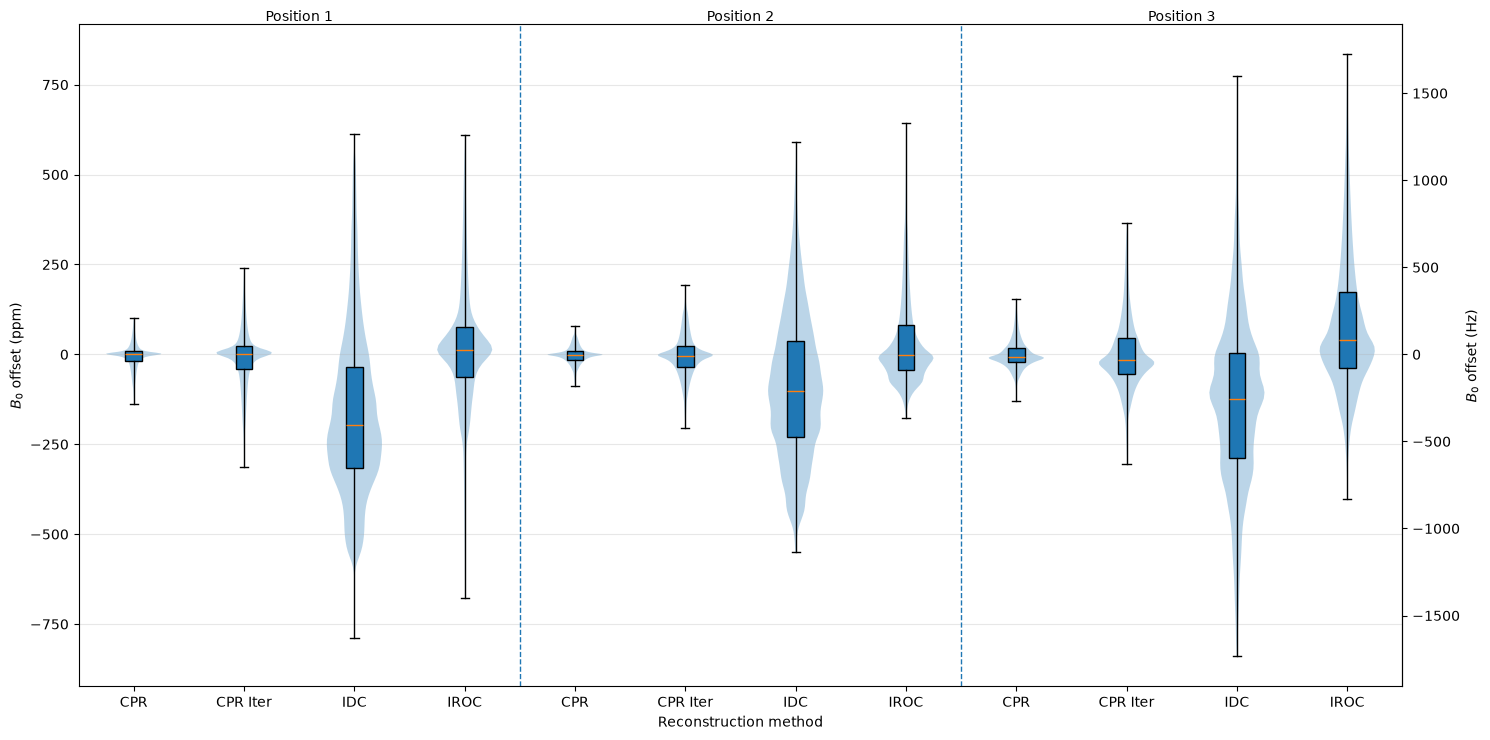

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Resonance frequency
# ============================================================

b1Freq = 2.0653615  # MHz


# ============================================================
# Combined violin + boxplot
# Grouped by position
#
# Position 1: CPR, CPR Iter, IDC, IROC
# Position 2: CPR, CPR Iter, IDC, IROC
# Position 3: CPR, CPR Iter, IDC, IROC
# ============================================================

plot_order = [

    # Position 1
    ("CPROne",  "Order04", "CPR",      "position1"),
    ("CPRIter", "Order04", "CPR Iter", "position1"),
    ("IDC",   None,      "IDC",    "position1"),
    ("IROC",    "Order12", "IROC",     "position1"),

    # Position 2
    ("CPROne",  "Order04", "CPR",      "position2"),
    ("CPRIter", "Order04", "CPR Iter", "position2"),
    ("IDC",   None,      "IDC",    "position2"),
    ("IROC",    "Order12", "IROC",     "position2"),

    # Position 3
    ("CPROne",  "Order04", "CPR",      "position3"),
    ("CPRIter", "Order04", "CPR Iter", "position3"),
    ("IDC",   None,      "IDC",    "position3"),
    ("IROC",    "Order12", "IROC",     "position3"),
]


# ============================================================
# Extract data
# ============================================================

data = []
labels = []

for technique, order, label, position in plot_order:

    # Get B0 map
    if technique == "IDC":
        b0 = b0_maps[position][technique]
    else:
        b0 = b0_maps[position][technique][order]

    # Apply position-specific mask
    mask = masks[position].astype(bool)

    values = b0[mask]

    # Remove NaN / infinite values
    values = values[np.isfinite(values)]

    # --------------------------------------------------------
    # Convert Hz -> ppm
    # b1Freq is in MHz, so this simplifies to:
    # ppm = Hz / MHz
    # --------------------------------------------------------

    values_ppm = values / b1Freq

    data.append(values_ppm)
    labels.append(label)


# ============================================================
# Plot
# ============================================================

fig, ax = plt.subplots(figsize=(15, 7.5))

# ------------------------------------------------------------
# Violin
# ------------------------------------------------------------

ax.violinplot(
    data,
    showmeans=False,
    showmedians=False,
    showextrema=False
)

# ------------------------------------------------------------
# Boxplot
# ------------------------------------------------------------



ax.boxplot(
    data,
    widths=0.15,
    showfliers=False,
    patch_artist=True,
    whis=(0, 100)
)


# ============================================================
# X-axis
# ============================================================

ax.set_xticks(np.arange(1, len(labels) + 1))
ax.set_xticklabels(labels)

ax.set_xlabel("Reconstruction method")
ax.set_ylabel(r"$B_0$ offset (ppm)")


# ============================================================
# Separate positions
# ============================================================

ax.axvline(
    4.5,
    linestyle="--",
    linewidth=1
)

ax.axvline(
    8.5,
    linestyle="--",
    linewidth=1
)


# ============================================================
# Position labels
# ============================================================

y_max = ax.get_ylim()[1]

ax.text(
    2.5,
    y_max,
    "Position 1",
    ha="center",
    va="bottom"
)

ax.text(
    6.5,
    y_max,
    "Position 2",
    ha="center",
    va="bottom"
)

ax.text(
    10.5,
    y_max,
    "Position 3",
    ha="center",
    va="bottom"
)


# ============================================================
# Grid and layout
# ============================================================

ax.grid(
    axis="y",
    alpha=0.3
)
# ============================================================
# Secondary y-axis: Hz
# ============================================================

secax = ax.secondary_yaxis(
    "right",
    functions=(
        lambda ppm: ppm * b1Freq,
        lambda hz: hz / b1Freq
    )
)

secax.set_ylabel(r"$B_0$ offset (Hz)")


plt.tight_layout()
plt.show()

In [12]:
import pandas as pd

results_ppm = []

for technique, order, label, position in plot_order:

    # Get B0 map
    if technique == "IDC":
        b0 = b0_maps[position][technique]
    else:
        b0 = b0_maps[position][technique][order]

    # Apply mask
    mask = masks[position].astype(bool)

    values = b0[mask]
    values = values[np.isfinite(values)]

    # Convert Hz -> ppm
    values_ppm = values / b1Freq

    # Peak-to-peak
    peak_to_peak = np.max(values_ppm) - np.min(values_ppm)

    results_ppm.append({
        "Position": position,
        "Technique": technique,
        "Peak_to_Peak_ppm": peak_to_peak
    })


pd_peak_to_peak_ppm = pd.DataFrame(results_ppm)

# Optional: round to 2 decimal places
pd_peak_to_peak_ppm["Peak_to_Peak_ppm"] = (
    pd_peak_to_peak_ppm["Peak_to_Peak_ppm"].astype(int)
)


# ---- Pivot for better readability ----

pd_peak_to_peak_ppm_pivot = (
    pd_peak_to_peak_ppm
    .pivot(
        index="Technique",
        columns="Position",
        values="Peak_to_Peak_ppm"
    )
    .reset_index()
)

# Rename columns
pd_peak_to_peak_ppm_pivot.columns = [
    "Technique",
    "Position 1",
    "Position 2",
    "Position 3"
]

# Round to integer
pd_peak_to_peak_ppm_pivot[
    ["Position 1", "Position 2", "Position 3"]
] = pd_peak_to_peak_ppm_pivot[
    ["Position 1", "Position 2", "Position 3"]
].round(0).astype(int)

technique_order = ["CPROne", "CPRIter", "IDC", "IROC"]

pd_peak_to_peak_ppm_pivot["Technique"] = pd.Categorical(
    pd_peak_to_peak_ppm_pivot["Technique"],
    categories=technique_order,
    ordered=True
)

pd_peak_to_peak_ppm_pivot = (
    pd_peak_to_peak_ppm_pivot
    .sort_values("Technique")
    .reset_index(drop=True)
)

pd_peak_to_peak_ppm_pivot

,Technique,Position 1,Position 2,Position 3
0,CPROne,239,168,283
1,CPRIter,553,398,670
2,IDC,1403,1141,1613
3,IROC,1288,818,1237


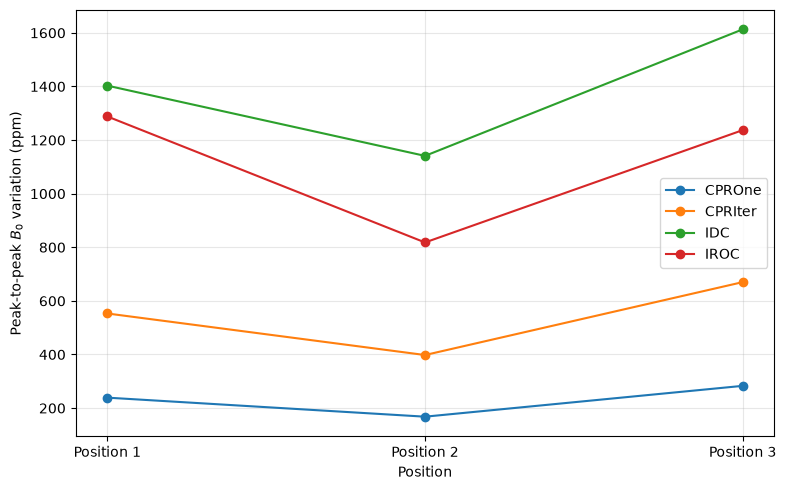

In [13]:
plt.figure(figsize=(8, 5))

for technique in pd_peak_to_peak_ppm["Technique"].unique():

    data = pd_peak_to_peak_ppm[
        pd_peak_to_peak_ppm["Technique"] == technique
    ]

    plt.plot(
        data["Position"].str.extract(r"(\d+)")[0].astype(int),
        data["Peak_to_Peak_ppm"],
        marker="o",
        linewidth=1.5,
        label=technique
    )

plt.xlabel("Position")
plt.ylabel(r"Peak-to-peak $B_0$ variation (ppm)")

plt.xticks(
    [1, 2, 3],
    ["Position 1", "Position 2", "Position 3"]
)

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

# Peak to Peak per slice

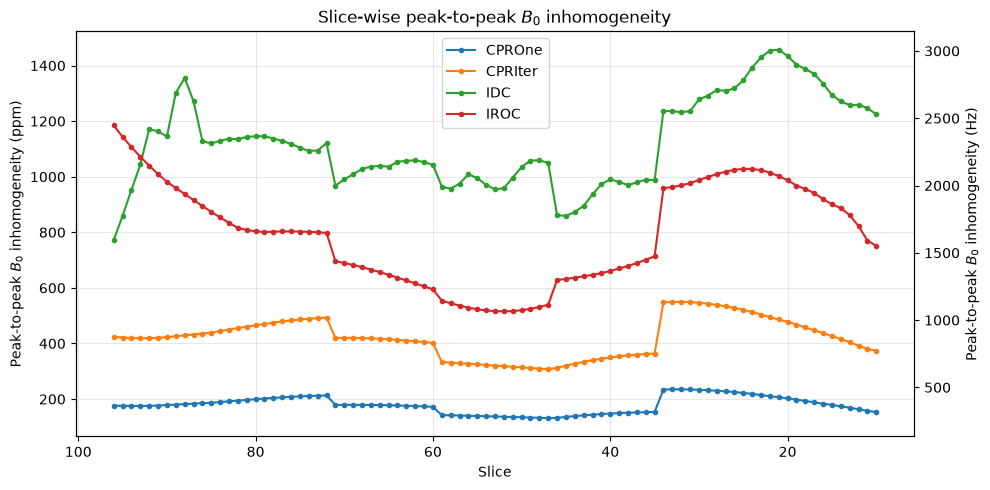

In [14]:
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# Select best-performing order for each technique
# ============================================================

selected = {
    "CPROne": ("CPROne", "Order04"),
    "CPRIter": ("CPRIter", "Order04"),
    "IDC": ("IDC", None),
    "IROC": ("IROC", "Order12"),
}


# ============================================================
# Mask each position and combine the 3 positions
# ============================================================

b0_combined = {}

for label, (technique, order) in selected.items():

    # Get reference shape
    reference = (
        b0_maps["position1"][technique]
        if technique == "IDC"
        else b0_maps["position1"][technique][order]
    )

    # Sum of B0 values
    combined = np.zeros_like(reference, dtype=float)

    # Number of contributions per voxel
    count = np.zeros_like(reference, dtype=float)

    for position in positions:

        # Get B0 map
        if technique == "IDC":
            b0 = b0_maps[position][technique]
        else:
            b0 = b0_maps[position][technique][order]

        # Apply position-specific mask
        mask = masks[position].astype(bool)

        # Add B0 values only inside mask
        combined += np.where(mask, b0, 0)

        # Count contributions
        count += mask.astype(float)

    # Average overlapping regions
    b0_combined[label] = np.divide(
        combined,
        count,
        out=np.zeros_like(combined),
        where=count > 0
    )

# Proton Larmor frequency
b1Freq = 2.0653615e6  # Hz


# ============================================================
# Slice-wise peak-to-peak B0
# ============================================================

plt.figure(figsize=(10, 5))

# Store results if needed later
peak_to_peak_hz = {}
peak_to_peak_ppm = {}

for technique in selected:

    b0 = b0_combined[technique]

    peak_to_peak_per_slice = []

    for z in range(b0.shape[2]):

        slice_data = b0[:, :, z]

        # Only include non-zero voxels
        values = slice_data[slice_data != 0]

        if len(values) > 0:
            # Peak-to-peak B0 range
            ptp = np.max(values) - np.min(values)
            peak_to_peak_per_slice.append(ptp)
        else:
            peak_to_peak_per_slice.append(np.nan)

    peak_to_peak_hz[technique] = np.array(peak_to_peak_per_slice)

    # Convert Hz -> ppm
    peak_to_peak_ppm[technique] = (
        peak_to_peak_hz[technique] / b1Freq * 1e6
    )

    # Plot ppm
    plt.plot(
        np.arange(b0.shape[2]),
        peak_to_peak_ppm[technique],
        marker="o",
        markersize=3,
        linewidth=1.5,
        label=technique
    )


# ============================================================
# Left axis: ppm
# ============================================================

ax = plt.gca()

ax.set_xlabel("Slice")
ax.set_ylabel(r"Peak-to-peak $B_0$ inhomogeneity (ppm)")
ax.set_title(r"Slice-wise peak-to-peak $B_0$ inhomogeneity")

ax.grid(alpha=0.3)


# ============================================================
# Right axis: Hz
# ============================================================

ax_hz = ax.twinx()



# Make the right axis correspond exactly to the left axis
ymin, ymax = ax.get_ylim()

ax_hz.set_ylim(
    ymin * b1Freq / 1e6,
    ymax * b1Freq / 1e6
)

ax_hz.set_ylabel(r"Peak-to-peak $B_0$ inhomogeneity (Hz)")


# ============================================================
# Formatting
# ============================================================

ax.legend()

plt.gca().invert_xaxis()
plt.tight_layout()
plt.show()